## 

## OMY Experiments

/tmp/ipykernel_1268265/3007981851.py:63: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_c.show()
/tmp/ipykernel_1268265/3007981851.py:64: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_t.show()


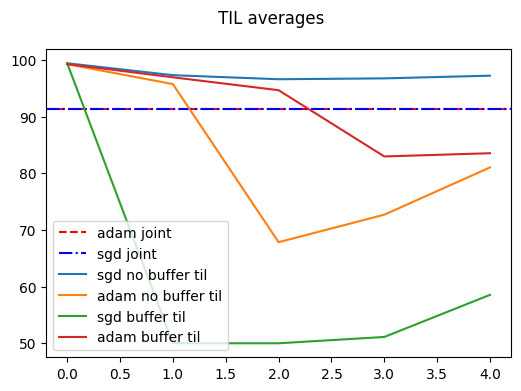

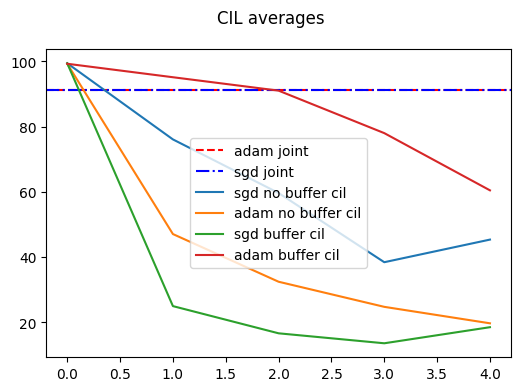

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

joint_acc_adam=91.35
joint_acc_sgd=91.29

# RESNET pretrained No buffer

no_buff_sgd_cil=[[99.4] ,[57.0, 95.15],[53.75, 27.7, 97.5],[35.25, 5.1, 14.1, 99.35],[20.3, 0.2, 27.0, 80.55, 98.85]  ]
no_buff_sgd_til=[[99.4] ,[99.45, 95.15],[96.8, 95.45, 97.5],[96.95, 95.5, 95.1, 99.4], [97.1, 95.4, 95.25, 99.4, 98.9]]


no_buff_adam_cil=[[99.25],[0.0, 94.15] ,[0.0, 0.0, 97.4] , [0.0, 0.0, 0.0, 99.1] ,[0.0, 0.0, 0.0, 0.0, 98.65]  ]
no_buff_adam_til=[[99.25] ,[97.3, 94.15],[56.1, 50.0, 97.4],[50.0, 75.2, 66.45, 99.1], [50.85, 64.25, 92.45, 98.9, 98.65]]

# RESNET pretrained buffer 1000
buff_sgd_cil=[[99.4] , [0.0, 50.0],[0.0, 0.0, 50.0],[0.0, 0.0, 0.0, 54.45],[0.0, 0.0, 0.0, 0.0, 92.7]   ]
buff_sgd_til=[[99.4] ,[50.0, 50.0],[50.0, 50.0, 50.0],[50.0, 50.0, 50.0, 54.45],[50.0, 50.0, 50.0, 50.0, 92.7]]

buff_adam_cil=[[99.25] ,[97.0, 93.25] ,[97.85, 85.4, 89.8],[97.75, 80.1, 86.8, 47.35],[93.2, 87.7, 78.75, 42.7, 0.0]   ]
buff_adam_til=[[99.25], [98.85, 95.0], [99.1, 93.2, 91.65],[98.85, 90.15, 89.95, 52.9],[96.95, 91.35, 83.85, 94.2, 51.3]]

fig_t, ax_t = plt.subplots(figsize=(6, 4))
fig_t.suptitle("TIL averages")

fig_c, ax_c = plt.subplots(figsize=(6, 4))
fig_c.suptitle("CIL averages")

ax_c.axhline(y=joint_acc_adam, color='r', linestyle='--', label='adam joint')
ax_c.axhline(y=joint_acc_sgd, color='b', linestyle='-.', label='sgd joint')
ax_t.axhline(y=joint_acc_adam, color='r', linestyle='--', label='adam joint')
ax_t.axhline(y=joint_acc_sgd, color='b', linestyle='-.', label='sgd joint')

# RESNET pretrained
CIL_avgs=[np.mean(l) for l in no_buff_sgd_cil]
ax_c.plot(CIL_avgs,label='sgd no buffer cil')
TIL_avgs=[np.mean(l) for l in no_buff_sgd_til]
ax_t.plot(TIL_avgs,label='sgd no buffer til')


# Hybrid scratch
CIL_avgs=[np.mean(l) for l in no_buff_adam_cil]
ax_c.plot(CIL_avgs,label='adam no buffer cil')

TIL_avgs=[np.mean(l) for l in no_buff_adam_til]
ax_t.plot(TIL_avgs,label='adam no buffer til')

# Hybrid pretrained
CIL_avgs=[np.mean(l) for l in buff_sgd_cil]
ax_c.plot(CIL_avgs,label='sgd buffer cil')

TIL_avgs=[np.mean(l) for l in buff_sgd_til]
ax_t.plot(TIL_avgs,label='sgd buffer til')

CIL_avgs=[np.mean(l) for l in buff_adam_cil]
ax_c.plot(CIL_avgs,label='adam buffer cil')

TIL_avgs=[np.mean(l) for l in buff_adam_til]
ax_t.plot(TIL_avgs,label='adam buffer til')

ax_t.legend()
ax_c.legend()
fig_c.show()
fig_t.show()


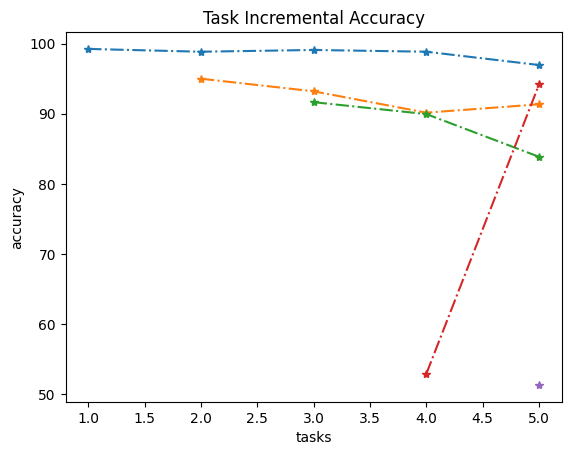

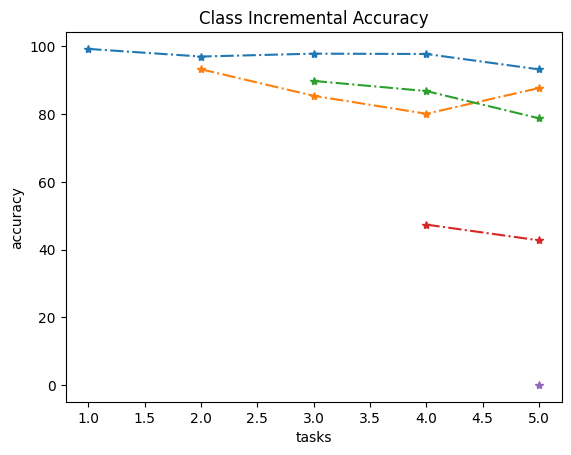

In [22]:

cmap=plt.get_cmap('tab10')
c=[cmap(i) for i in np.linspace(0,1,5)]
plt.figure()
plt.title('Task Incremental Accuracy')
plt.xlabel('tasks')
plt.ylabel('accuracy')
for i in range(5):
    k=[l[i] for l in buff_adam_til[i:]]
    plt.plot(np.arange(i+1,5+1),k,'*-.')
    
plt.figure()
plt.title('Class Incremental Accuracy')
plt.xlabel('tasks')
plt.ylabel('accuracy')
for i in range(5):
    k=[l[i] for l in buff_adam_cil[i:]]
    plt.plot(np.arange(i+1,5+1),k,'*-.')

In [40]:

filename = f'../debug_data_adam_buff1000/stats_task_1.pt'
print(filename)
data = torch.load(filename)

../debug_data_adam_buff1000/stats_task_1.pt


In [43]:
data['losses']

[{'main_grad': {'g_in': tensor([[-4.3727e-01, -4.3643e-01, -3.9247e-02,  ..., -7.3271e-02,
            -1.9495e-01, -4.7165e-03],
           [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  ...,  0.0000e+00,
             0.0000e+00,  0.0000e+00],
           [-4.3792e-01, -4.2179e-01, -2.1350e-02,  ..., -7.6239e-02,
            -1.9780e-01, -4.8369e-03],
           ...,
           [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  ...,  0.0000e+00,
             0.0000e+00,  0.0000e+00],
           [-3.4180e-01, -3.2057e-01,  1.7579e-03,  ..., -5.6826e-02,
            -1.5223e-01,  4.8314e-05],
           [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  ...,  0.0000e+00,
             0.0000e+00,  0.0000e+00]]),
   'g_rec': tensor([[-1.6927,  0.0000, -1.3584,  ...,  0.0000, -1.5573,  0.0000],
           [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
           [-1.7127,  0.0000, -1.3706,  ...,  0.0000, -1.5711,  0.0000],
           ...,
           [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000, 

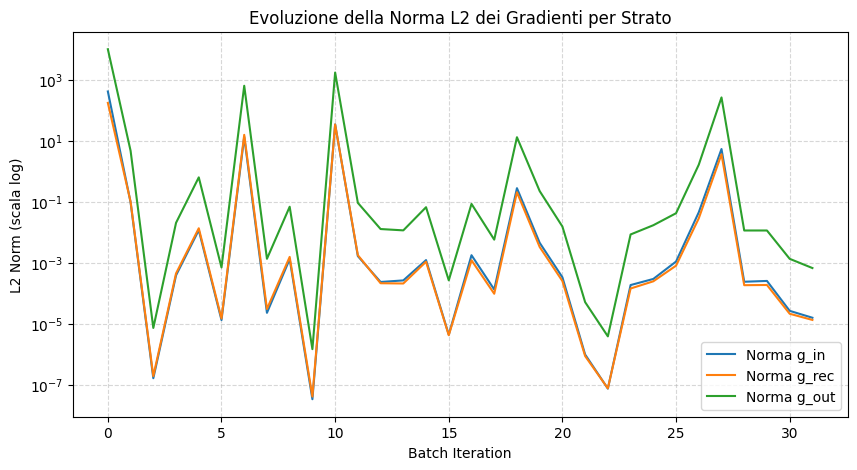

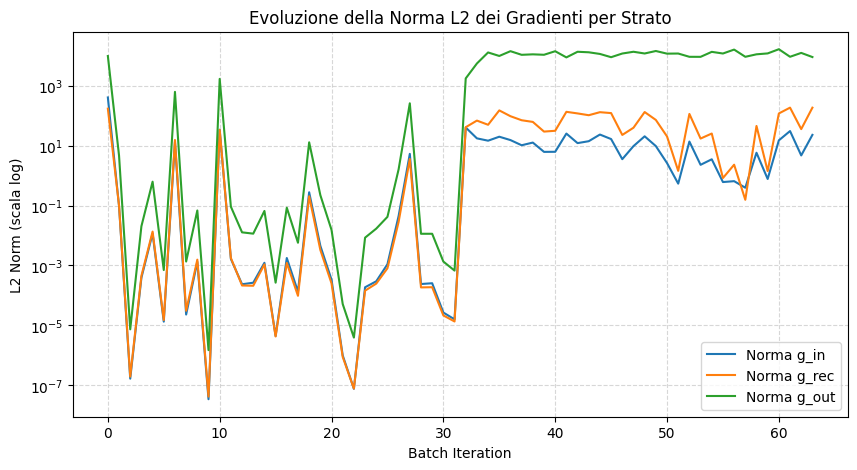

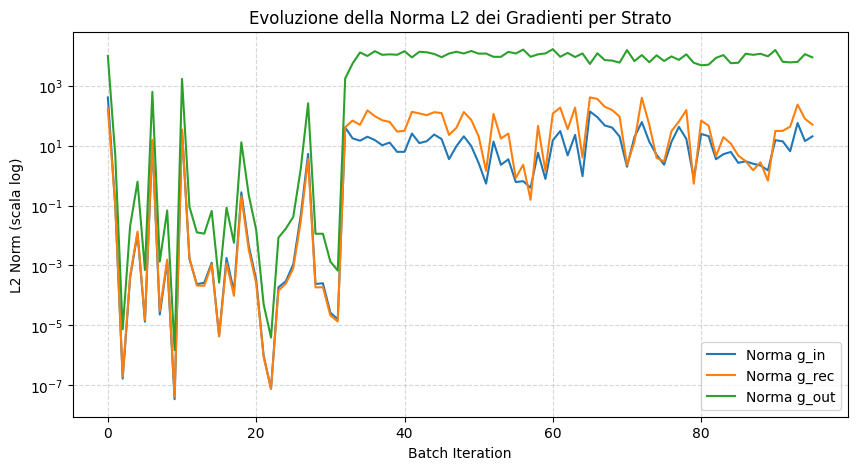

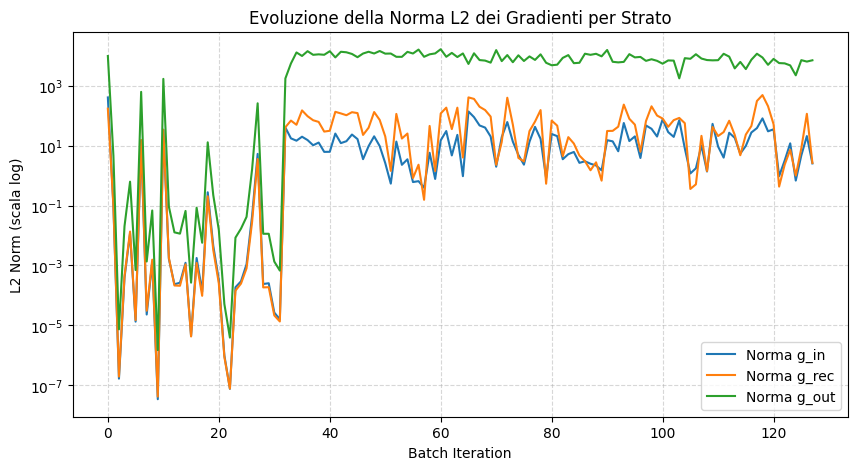

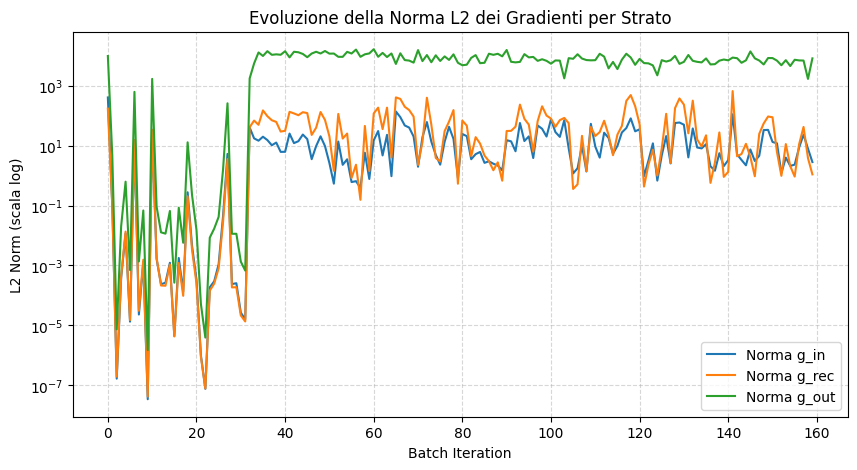

In [48]:

# Liste per salvare le norme dei gradienti per ogni strato
grad_norms = {
    'g_in': [],
    'g_rec': [],
    'g_out': []
}


# Dentro il tuo training loop:
for i in range(5):
    filename = f'../debug_data_nologits/stats_task_{i}.pt'
    data = torch.load(filename)
    for d in data['grads']:
        for key in grad_norms.keys():
            g_tensor = d['main_grad'][key]
            grad_norms[key].append(torch.norm(g_tensor, p=2).item())
    
    # --- PLOT DELLE NORME DEI GRADIENTI ---
    plt.figure(figsize=(10, 5))
    for key, values in grad_norms.items():
        plt.plot(values, label=f'Norma {key}')

    plt.yscale('log')  # Scala logaritmica fondamentale per vedere variazioni di ordini di grandezza!
    plt.title("Evoluzione della Norma L2 dei Gradienti per Strato")
    plt.xlabel("Batch Iteration")
    plt.ylabel("L2 Norm (scala log)")
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.legend()
    plt.show()

shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])


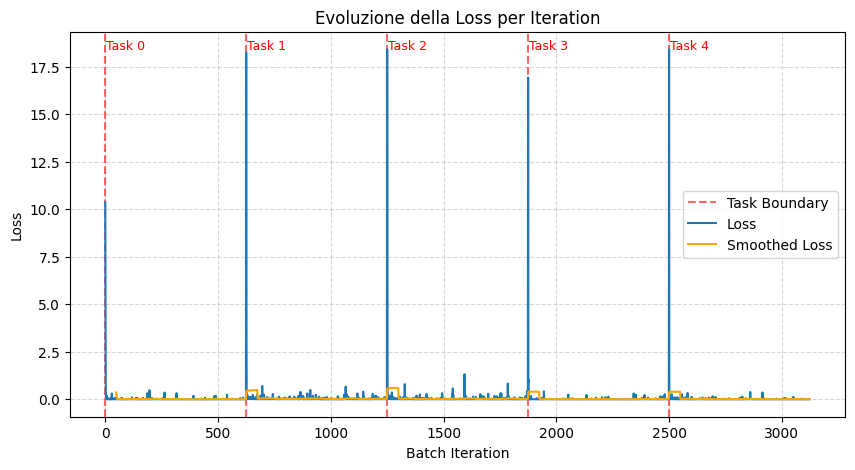

In [56]:
losses=[]
task_boundaries = []
# Dentro il tuo training loop:
for i in range(5):
    filename = f'../debug_data_sgd_no_buff_nll/stats_task_{i}.pt'
    data = torch.load(filename)
    task_boundaries.append(len(losses))
    print('shape of errors',data['errors'][0].shape) # lr_win, batch_size, num_classes
    print('shape of errors mean',data['errors'][0].mean().shape)
    for d in data['losses']:
        losses.append(d)
    
# --- PLOT DELLE NORME DEI GRADIENTI ---
plt.figure(figsize=(10, 5))
# Aggiungiamo linee verticali per evidenziare il cambio di Task (Continual Learning)
for task_idx, boundary in enumerate(task_boundaries):
    plt.axvline(
        x=boundary,
        color="red",
        linestyle="--",
        alpha=0.6,
        label="Task Boundary" if task_idx == 0 else "",
    )
    plt.text(
        boundary + 5,
        max(losses),
        f"Task {task_idx}",
        color="red",
        fontsize=9,
    )
plt.plot(losses, label='Loss')
# plt.yscale('log')
plt.title("Evoluzione della Loss per Iteration")
plt.xlabel("Batch Iteration")
plt.ylabel("Loss")

#sliding window smoothing
window_size = 50
smoothed_losses = np.convolve(losses, np.ones(window_size)/window_size, mode='valid')
plt.plot(range(window_size-1, len(losses)), smoothed_losses, label='Smoothed Loss', color='orange')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()


shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])


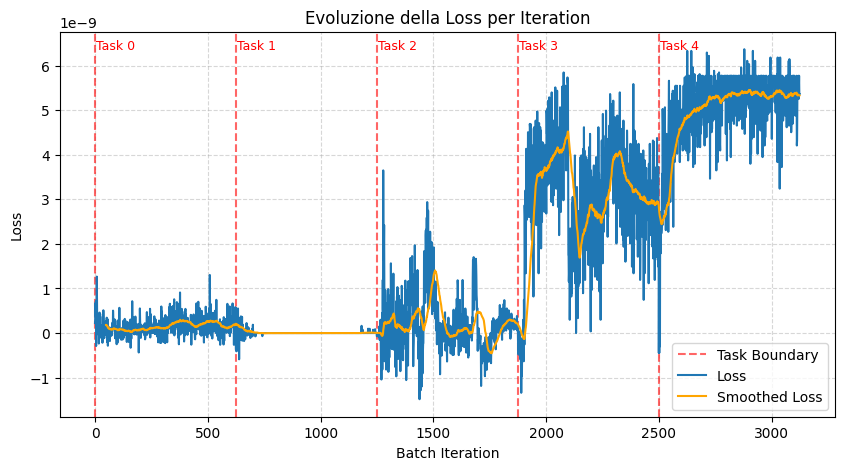

In [ ]:
losses=[]
task_boundaries = []
# Dentro il tuo training loop:
for i in range(5):
    filename = f'../debug_data_test/stats_task_{i}.pt'
    data = torch.load(filename)
    task_boundaries.append(len(losses))
    print('shape of errors',data['errors'][0].shape) # lr_win, batch_size, num_classes
    print('shape of errors mean',data['errors'][0].mean().shape)
    for d in data['errors']:
        losses.append(d.mean().item())
    
# --- PLOT DELLE NORME DEI GRADIENTI ---
plt.figure(figsize=(10, 5))
# Aggiungiamo linee verticali per evidenziare il cambio di Task (Continual Learning)
for task_idx, boundary in enumerate(task_boundaries):
    plt.axvline(
        x=boundary,
        color="red",
        linestyle="--",
        alpha=0.6,
        label="Task Boundary" if task_idx == 0 else "",
    )
    plt.text(
        boundary + 5,
        max(losses),
        f"Task {task_idx}",
        color="red",
        fontsize=9,
    )
plt.plot(losses, label='Loss')
# plt.yscale('log')
plt.title("Evoluzione della Loss per Iteration")
plt.xlabel("Batch Iteration")
plt.ylabel("Loss")

#sliding window smoothing
window_size = 50
smoothed_losses = np.convolve(losses, np.ones(window_size)/window_size, mode='valid')
plt.plot(range(window_size-1, len(losses)), smoothed_losses, label='Smoothed Loss', color='orange')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()


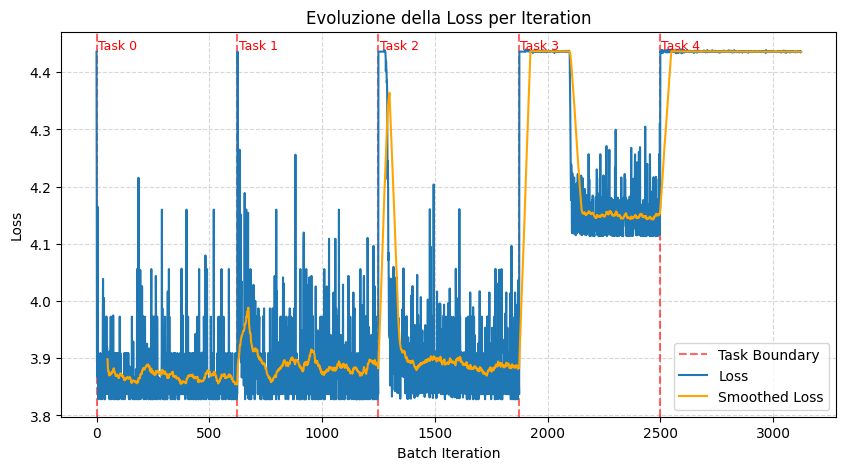

In [ ]:
losses=[]
task_boundaries = []
# Dentro il tuo training loop:
for i in range(5):
    filename = f'../debug_data_test/stats_task_{i}.pt'
    data = torch.load(filename)
    task_boundaries.append(len(losses))
    for d in data['losses']:
        losses.append(d)
    
# --- PLOT DELLE NORME DEI GRADIENTI ---
plt.figure(figsize=(10, 5))
# Aggiungiamo linee verticali per evidenziare il cambio di Task (Continual Learning)
for task_idx, boundary in enumerate(task_boundaries):
    plt.axvline(
        x=boundary,
        color="red",
        linestyle="--",
        alpha=0.6,
        label="Task Boundary" if task_idx == 0 else "",
    )
    plt.text(
        boundary + 5,
        max(losses),
        f"Task {task_idx}",
        color="red",
        fontsize=9,
    )
plt.plot(losses, label='Loss')
# plt.yscale('log')
plt.title("Evoluzione della Loss per Iteration")
plt.xlabel("Batch Iteration")
plt.ylabel("Loss")

#sliding window smoothing
window_size = 50
smoothed_losses = np.convolve(losses, np.ones(window_size)/window_size, mode='valid')
plt.plot(range(window_size-1, len(losses)), smoothed_losses, label='Smoothed Loss', color='orange')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()


## OPEN THE AUTOSAVED RESULTS in data/results

In [11]:

import torch

# Map 'device' to PyTorch's device constructor function
device = torch.device

log = []
with open('../data/results/class-il/seq-cifar10/sgd_snn/logs.pyd', 'r') as f:
    for line in f:
        if line.strip():
            log.append(eval(line.strip()))

dict_keys(['task_id', 'weights', 'firing_rates', 'labels', 'grads', 'outputs', 'errors', 'losses'])
losses 3125 6.3967366218566895


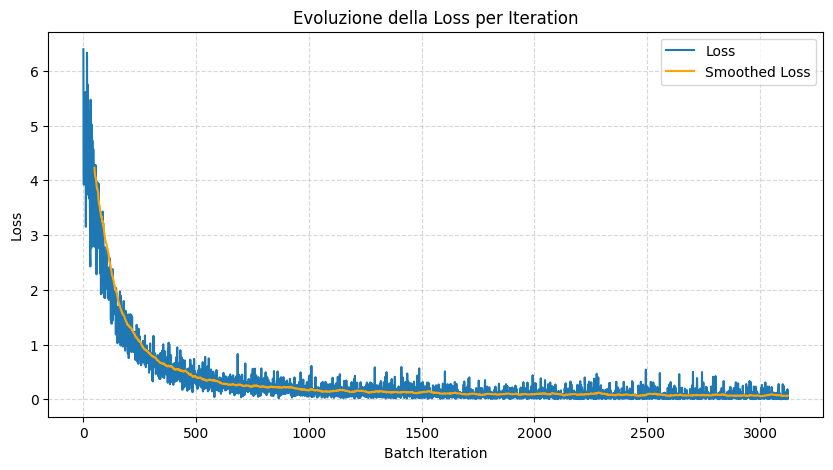

In [11]:
import matplotlib.pyplot as plt
import torch 
import numpy as np
losses=[]
# Dentro il tuo training loop:

filename = f'../debug_data_nologits/stats_task_0.pt'
# filename = f'../loss_joint_lr_000000005/stats_task_0.pt'
# filename = f'../debug_data_sgd_joint/stats_task_0.pt'
data = torch.load(filename)
print(data.keys())
# for d in data['errors']:
#     losses.append(d.mean().item())

for d in data['losses']:
    losses.append(d)
print('losses',len(losses),losses[0])
# --- PLOT DELLE NORME DEI GRADIENTI ---
plt.figure(figsize=(10, 5))
# Aggiungiamo linee verticali per evidenziare il cambio di Task (Continual Learning)

plt.plot(losses, label='Loss')
# plt.yscale('log')
plt.title("Evoluzione della Loss per Iteration")
plt.xlabel("Batch Iteration")
plt.ylabel("Loss")

#sliding window smoothing
window_size = 50
smoothed_losses = np.convolve(losses, np.ones(window_size)/window_size, mode='valid')
plt.plot(range(window_size-1, len(losses)), smoothed_losses, label='Smoothed Loss', color='orange')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()


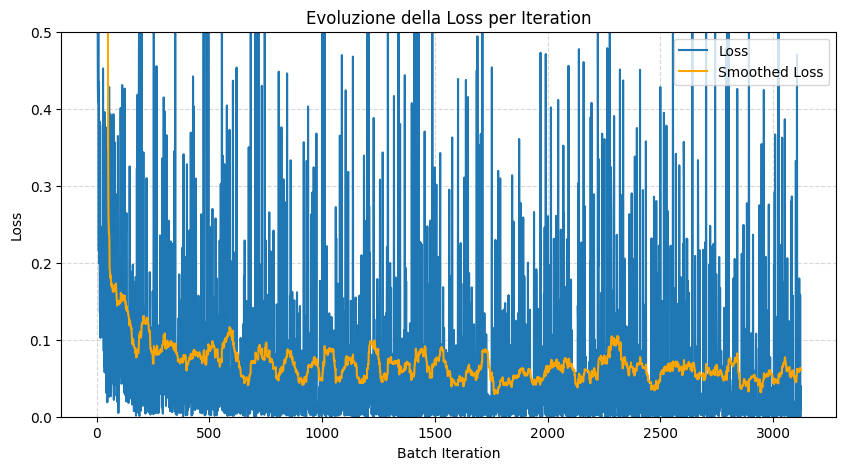

In [59]:
plt.figure(figsize=(10, 5))
# Aggiungiamo linee verticali per evidenziare il cambio di Task (Continual Learning)

plt.plot(losses, label='Loss')
# plt.yscale('log')
plt.title("Evoluzione della Loss per Iteration")
plt.xlabel("Batch Iteration")
plt.ylabel("Loss")

#sliding window smoothing
window_size = 50
smoothed_losses = np.convolve(losses, np.ones(window_size)/window_size, mode='valid')
plt.plot(range(window_size-1, len(losses)), smoothed_losses, label='Smoothed Loss', color='orange')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.ylim(0, 0.5)  # Imposta i limiti dell'asse y per una visualizzazione più chiara
plt.show()


In [37]:
import torch
checkpoint = torch.load("../checkpoints/resnet18_scifar10_sgd_joint_inference.pt")
checkpoint['optimizer']['param_groups']
if isinstance(checkpoint, dict) and 'model' in checkpoint:
    # Caso standard di Mammoth: i pesi sono dentro la chiave 'model'
    weights_only = checkpoint['model']
    print("Trovata chiave 'model'. Estrazione dei pesi completata.")
new_ckpt_path = "../checkpoints/resnet18_scifar10_weights_only.pt"
torch.save(weights_only, new_ckpt_path)
print(f"Nuovo checkpoint con SOLI pesi salvato in: {new_ckpt_path}")

Trovata chiave 'model'. Estrazione dei pesi completata.
Nuovo checkpoint con SOLI pesi salvato in: ../checkpoints/resnet18_scifar10_weights_only.pt


dict_keys(['task_id', 'losses'])
losses 17600 2.3781614303588867


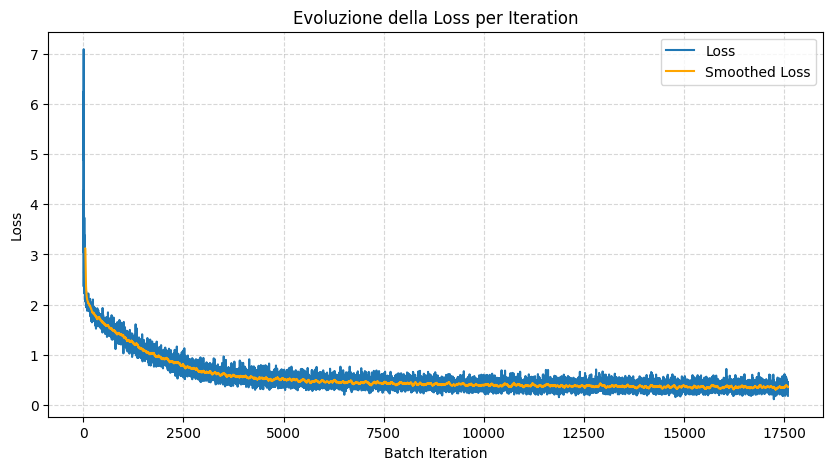

In [51]:

import matplotlib.pyplot as plt
losses=[]
# Dentro il tuo training loop:
filename = f'../losses_resnet/stats_task_0.pt'
data = torch.load(filename)
print(data.keys())
# for d in data['errors']:
#     losses.append(d.mean().item())

for d in data['losses']:
    losses.append(d)
print('losses',len(losses),losses[0])
# --- PLOT DELLE NORME DEI GRADIENTI ---
plt.figure(figsize=(10, 5))
# Aggiungiamo linee verticali per evidenziare il cambio di Task (Continual Learning)

plt.plot(losses, label='Loss')
# plt.yscale('log')
plt.title("Evoluzione della Loss per Iteration")
plt.xlabel("Batch Iteration")
plt.ylabel("Loss")

#sliding window smoothing
window_size = 50
smoothed_losses = np.convolve(losses, np.ones(window_size)/window_size, mode='valid')
plt.plot(range(window_size-1, len(losses)), smoothed_losses, label='Smoothed Loss', color='orange')
plt.grid(True, which="both", linestyle="--", alpha=0.5)

plt.legend()
plt.show()


In [52]:

filename = f'../debug_data_adam_no_buff/stats_task_0.pt'
data = torch.load(filename)
print(data.keys())

dict_keys(['task_id', 'weights', 'firing_rates', 'labels', 'losses', 'outputs'])


/tmp/ipykernel_1416528/440195079.py:71: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_c.show()
/tmp/ipykernel_1416528/440195079.py:72: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_t.show()


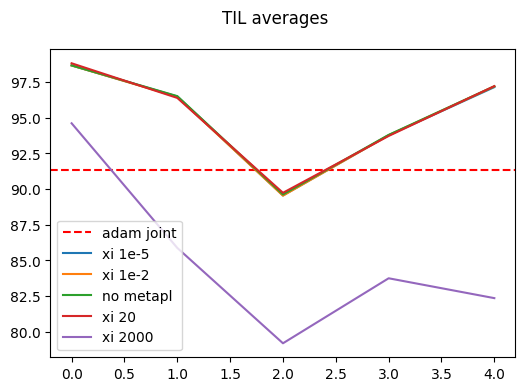

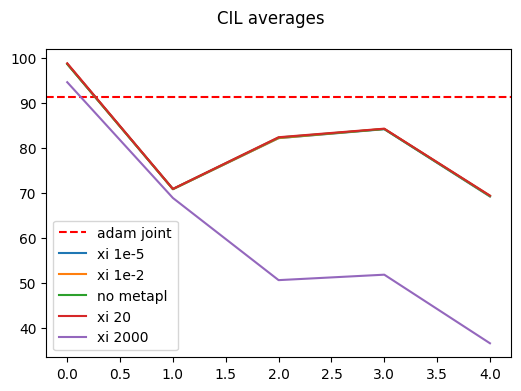

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

joint_acc_adam=91.35




# RESNET pretrained buffer
metapl_1e5_cil=[[98.65],[46.7, 95.0],[92.5, 69.3, 84.75],[98.55, 85.3, 60.85, 92.0],[69.35, 93.65, 70.55, 25.95, 86.65]]
metapl_1e5_til=[[98.65],[97.95, 95.0],[99.2, 73.15, 96.3],[99.05, 95.35, 82.35, 98.3],[99.05, 94.85, 96.1, 98.25, 97.4]]


# RESNET pretrained buffer
metapl_1e2_cil=[[98.65],[46.7, 95.0],[92.5, 69.2, 84.9],[98.6, 85.4, 61.0, 91.95],[69.55, 93.8, 70.4, 26.1, 86.75]]
metapl_1e2_til=[[98.65],[97.9, 95.0],[99.2, 73.15, 96.25],[99.05, 95.3, 82.45, 98.25],[99.1, 94.95, 96.2, 98.2, 97.45]]



# RESNET pretrained buffer
no_metapl_cil=[[98.65],[46.75, 95.05],[92.45, 69.6, 84.9],[98.6, 85.45, 60.75, 92.05],[69.5, 93.75, 70.65, 26.05, 86.8]]
no_metapl_til=[[98.65],[97.95, 95.05],[99.2, 73.4, 96.25],[99.05, 95.4, 82.35, 98.35],[99.1, 95.0, 96.25, 98.2, 97.4]]


# RESNET pretrained buffer
metapl_20_cil=[[98.8],[46.95, 94.9],[92.55, 69.75, 84.85],[98.6, 85.25, 61.35, 91.95],[69.75, 93.85, 71.15, 25.7, 86.75]]
metapl_20_til=[[98.8],[97.85, 94.9],[99.2, 73.7, 96.3],[99.05, 95.3, 82.2, 98.3],[99.1, 95.15, 96.1, 98.25, 97.4]]

# RESNET pretrained buffer
metapl_2000_cil=[[94.6],[60.9, 76.9],[54.5, 20.4, 77.1],[56.65, 17.1, 42.9, 90.85],[1.1, 22.6, 43.4, 47.55, 68.6]]
metapl_2000_til=[[94.6],[84.15, 87.6],[85.35, 62.9, 89.35],[94.0, 66.64999999999999, 77.60000000000001, 96.75],[87.85, 57.3, 77.9, 95.55, 93.2]]


fig_t, ax_t = plt.subplots(figsize=(6, 4))
fig_t.suptitle("TIL averages")

fig_c, ax_c = plt.subplots(figsize=(6, 4))
fig_c.suptitle("CIL averages")

ax_c.axhline(y=joint_acc_adam, color='r', linestyle='--', label='adam joint')
ax_t.axhline(y=joint_acc_adam, color='r', linestyle='--', label='adam joint')

# RESNET pretrained
CIL_avgs=[np.mean(l) for l in metapl_1e5_cil]
ax_c.plot(CIL_avgs,label='xi 1e-5')
TIL_avgs=[np.mean(l) for l in metapl_1e5_til]
ax_t.plot(TIL_avgs,label='xi 1e-5')

CIL_avgs=[np.mean(l) for l in metapl_1e2_cil]
ax_c.plot(CIL_avgs,label='xi 1e-2')
TIL_avgs=[np.mean(l) for l in metapl_1e2_til]
ax_t.plot(TIL_avgs,label='xi 1e-2')

CIL_avgs=[np.mean(l) for l in no_metapl_cil]
ax_c.plot(CIL_avgs,label='no metapl')
TIL_avgs=[np.mean(l) for l in no_metapl_til]
ax_t.plot(TIL_avgs,label='no metapl')

CIL_avgs=[np.mean(l) for l in metapl_20_cil]
ax_c.plot(CIL_avgs,label='xi 20')
TIL_avgs=[np.mean(l) for l in metapl_20_til]
ax_t.plot(TIL_avgs,label='xi 20')

CIL_avgs=[np.mean(l) for l in metapl_2000_cil]
ax_c.plot(CIL_avgs,label='xi 2000')
TIL_avgs=[np.mean(l) for l in metapl_2000_til]
ax_t.plot(TIL_avgs,label='xi 2000')

ax_t.legend()
ax_c.legend()
fig_c.show()
fig_t.show()


In [ ]:
log

[{'loadcheck': None,
  'dataset': 'seq-cifar10',
  'model': 'sgd-snn',
  'backbone': 'resnet18cus',
  'load_best_args': False,
  'dataset_config': 'default',
  'model_config': 'default',
  'transform_type': 'weak',
  'srnn_hidden_size': 150,
  'n_in': 512,
  'n_out': 10,
  'n_t': 100,
  'thr': 0.6,
  'tau_m': 30.0,
  'tau_o': 100.0,
  'b_o': 0.0,
  'gamma': 0.5,
  'dt': 1.0,
  'classif': True,
  'keep_sparsity': False,
  'syn_scale': False,
  'sparsity': (0.0, 0.0, 0.0),
  'lr_layer': (0.5, 0.5, 0.5),
  'f_target': 100,
  'c_reg': 0.001,
  'lr_win': 10,
  'net_state': './checkpoints/resnet18_scifar10_sgd_joint_inference.pt',
  'xi': 20.0,
  'num_classes': 10,
  'num_filters': 64,
  'seed': 0,
  'permute_classes': False,
  'base_path': './data/',
  'checkpoint_path': './checkpoints/',
  'results_path': 'results/',
  'device': device(type='cuda', index=0),
  'notes': 'training RESNET on SCIFAR10',
  'eval_epochs': None,
  'non_verbose': False,
  'disable_log': False,
  'num_workers': Non

In [40]:

print(np.mean(metapl_1e5_cil[-1]))
print(np.mean(metapl_1e2_cil[-1]))
print(np.mean(no_metapl_cil[-1]))
print(np.mean(metapl_20_cil[-1]))
print(np.mean(metapl_2000_cil[-1]))

69.22999999999999
69.32000000000001
69.35
69.44
36.65


shape of errors (task 0) torch.Size([10, 16, 10])
shape of errors (task 1) torch.Size([10, 16, 10])
shape of errors (task 2) torch.Size([10, 16, 10])
shape of errors (task 3) torch.Size([10, 16, 10])
shape of errors (task 4) torch.Size([10, 16, 10])


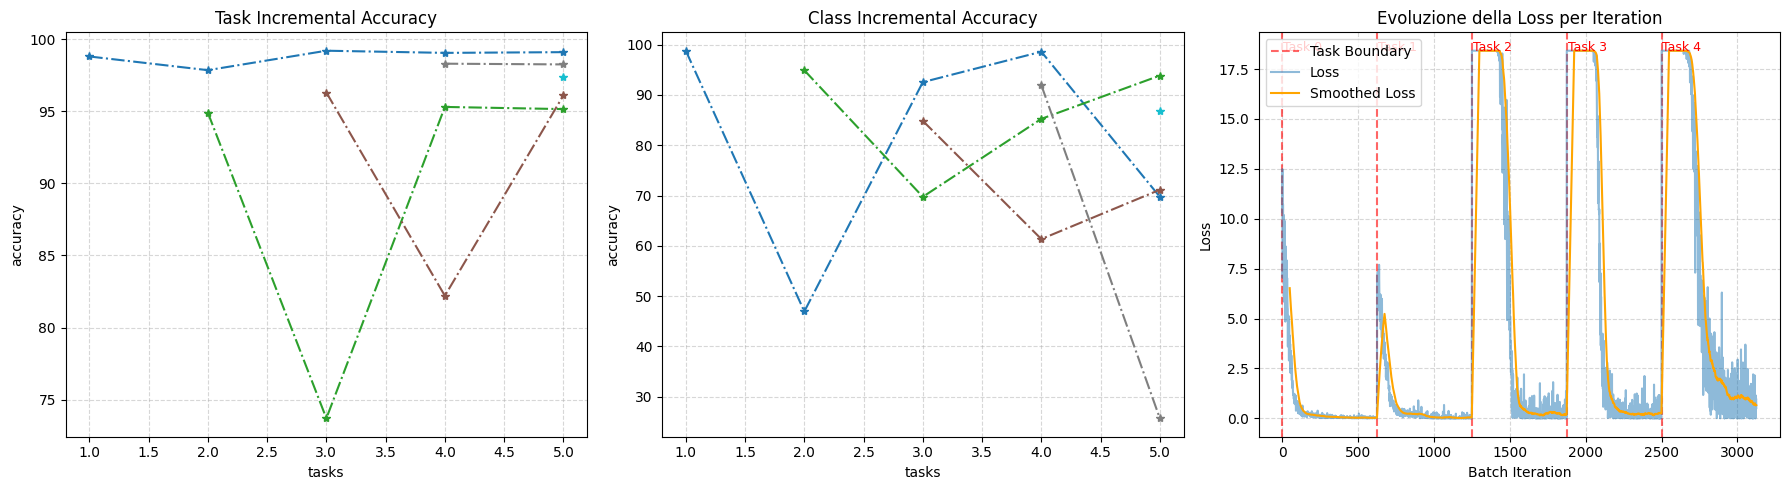

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
title=
filename=
data_til=metapl_20_til
data_cil=metapl_20_cil
# Creiamo una figura unica con 3 subplot in 1 riga e 3 colonne
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- 1. Task Incremental Accuracy ---
cmap = plt.get_cmap('tab10')
c = [cmap(i) for i in np.linspace(0, 1, 5)]

axes[0].set_title('Task Incremental Accuracy')
axes[0].set_xlabel('tasks')
axes[0].set_ylabel('accuracy')
for i in range(5):
    k = [l[i] for l in data_til[i:]]
    axes[0].plot(np.arange(i+1, 5+1), k, '*-.', color=c[i])
axes[0].grid(True, linestyle="--", alpha=0.5)


# --- 2. Class Incremental Accuracy ---
axes[1].set_title('Class Incremental Accuracy')
axes[1].set_xlabel('tasks')
axes[1].set_ylabel('accuracy')
for i in range(5):
    k = [l[i] for l in data_cil[i:]]
    axes[1].plot(np.arange(i+1, 5+1), k, '*-.', color=c[i])
axes[1].grid(True, linestyle="--", alpha=0.5)


# --- 3. Evoluzione della Loss ---
losses = []
task_boundaries = []

for i in range(5):
    filename = f'../filename/stats_task_{i}.pt'
    data = torch.load(filename)
    task_boundaries.append(len(losses))
    print(f'shape of errors (task {i})', data['errors'][0].shape)
    
    for d in data['losses']:
        losses.append(d)

# Linee verticali per evidenziare il cambio di Task
for task_idx, boundary in enumerate(task_boundaries):
    axes[2].axvline(
        x=boundary,
        color="red",
        linestyle="--",
        alpha=0.6,
        label="Task Boundary" if task_idx == 0 else "",
    )
    axes[2].text(
        boundary + 5,
        max(losses),
        f"Task {task_idx}",
        color="red",
        fontsize=9,
    )

axes[2].plot(losses, label='Loss', alpha=0.5)

# Sliding window smoothing
window_size = 50
smoothed_losses = np.convolve(losses, np.ones(window_size)/window_size, mode='valid')
axes[2].plot(range(window_size-1, len(losses)), smoothed_losses, label='Smoothed Loss', color='orange')

axes[2].set_title("Evoluzione della Loss per Iteration")
axes[2].set_xlabel("Batch Iteration")
axes[2].set_ylabel("Loss")
axes[2].grid(True, which="both", linestyle="--", alpha=0.5)
axes[2].legend()

plt.suptitle(title)
# Ottimizza lo spazio tra i subplot ed evita sovrapposizioni
plt.tight_layout()
plt.show()

/tmp/ipykernel_1416528/2286978596.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_c.show()
/tmp/ipykernel_1416528/2286978596.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_t.show()


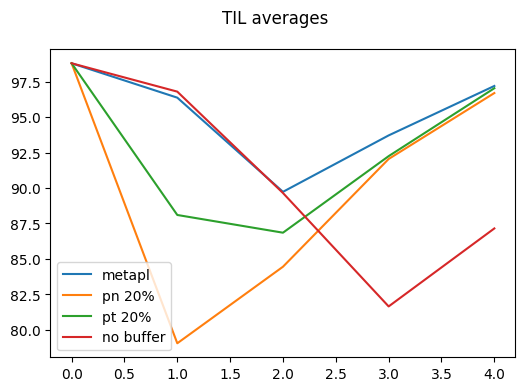

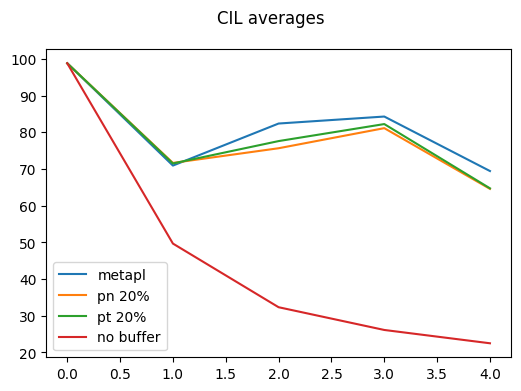

In [49]:
adam_lr1e5_buff_pn2_cil=[[98.8],[48.5, 94.8],[86.5, 55.6, 84.85],[98.2, 82.35, 51.15, 92.8],[59.2, 91.35, 63.55, 19.95, 88.85]]
adam_lr1e5_buff_pn2_til=[[98.8],[63.3, 94.8],[98.3, 58.5, 96.55],[99.2, 95.4, 74.9, 98.7],[99.1, 91.85, 96.0, 98.75, 97.8]]

adam_lr1e5_buff_pt2_cil=[[98.8], [48.1, 94.9] ,[85.5, 61.95, 85.35],[98.45, 85.0, 53.4, 92.1],[60.25, 93.75, 64.2, 17.5, 87.95]]
adam_lr1e5_buff_pt2_til=[[98.8],[81.3, 94.9],[98.65, 65.6, 96.3],[99.25, 95.45, 75.9, 98.4],[99.1, 94.2, 96.3, 98.5, 97.1]]


adam_lr1e5_no_buff_cil=[[98.8],[5.0, 94.35],[0.0, 0.7, 96.3],[0.0, 0.0, 6.15, 98.4],[0.0, 0.05, 9.0, 5.7, 97.8]]
adam_lr1e5_no_buff_til=[[98.8],[98.95, 94.65],[98.15, 74.5, 96.3],[79.9, 60.45, 87.35, 98.9],[95.9, 50.45, 93.7, 97.9, 97.8]]




fig_t, ax_t = plt.subplots(figsize=(6, 4))
fig_t.suptitle("TIL averages")

fig_c, ax_c = plt.subplots(figsize=(6, 4))
fig_c.suptitle("CIL averages")


CIL_avgs=[np.mean(l) for l in metapl_20_cil]
ax_c.plot(CIL_avgs,label='metapl')
TIL_avgs=[np.mean(l) for l in metapl_20_til]
ax_t.plot(TIL_avgs,label='metapl')

# RESNET pretrained
CIL_avgs=[np.mean(l) for l in adam_lr1e5_buff_pn2_cil]
ax_c.plot(CIL_avgs,label='pn 20%')
TIL_avgs=[np.mean(l) for l in adam_lr1e5_buff_pn2_til]
ax_t.plot(TIL_avgs,label='pn 20%')

CIL_avgs=[np.mean(l) for l in adam_lr1e5_buff_pt2_cil]
ax_c.plot(CIL_avgs,label='pt 20%')
TIL_avgs=[np.mean(l) for l in adam_lr1e5_buff_pt2_til]
ax_t.plot(TIL_avgs,label='pt 20%')

# RESNET pretrained
CIL_avgs=[np.mean(l) for l in adam_lr1e5_no_buff_cil]
ax_c.plot(CIL_avgs,label='no buffer')
TIL_avgs=[np.mean(l) for l in adam_lr1e5_no_buff_til]
ax_t.plot(TIL_avgs,label='no buffer')
ax_t.legend()
ax_c.legend()
fig_c.show()
fig_t.show()

